In [4]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, os
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import f_classif

df = pd.read_csv("spotgentrack_clean.csv")
train = df[df["split"] == "train"].reset_index(drop=True)
NOT_FEATURES = ["id", "song_id", "split", "popularity", "pop_class"]
X = train.drop(columns=NOT_FEATURES)
y = train["pop_class"]
print(X.shape)

(71065, 49)


In [5]:
r = X.corrwith(train["popularity"])
F, _ = f_classif(X, y)
filt = pd.DataFrame({"pearson_r": r, "abs_r": r.abs(), "anova_F": F},
                    index=X.columns).sort_values("abs_r", ascending=False).round(3)
filt.to_csv("fs_filter_ranking.csv")
filt.head(15)

,pearson_r,abs_r,anova_F
artist_popularity,0.702,0.702,21444.304
log_followers,0.555,0.555,10891.314
speechiness,-0.305,0.305,1126.451
genre_broad_unknown,-0.268,0.268,1737.906
loudness,0.242,0.242,812.335
time_signature_4,0.168,0.168,384.406
genre_broad_other,-0.157,0.157,482.054
genre_broad_latin,0.151,0.151,627.946
acousticness,-0.148,0.148,342.220
energy,0.147,0.147,214.947


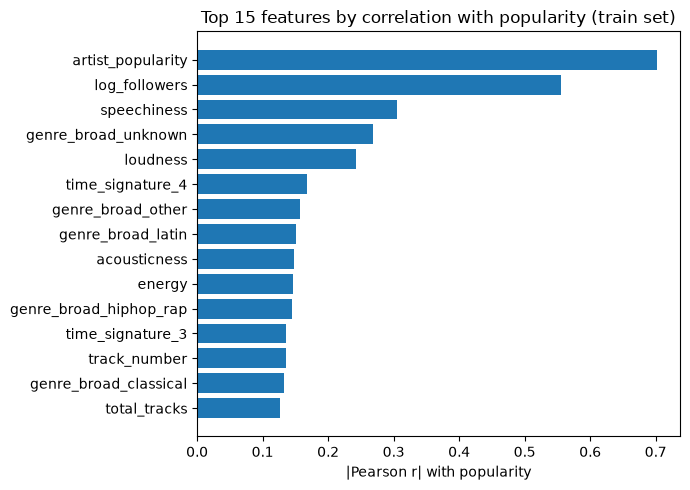

In [6]:
os.makedirs("figures", exist_ok=True)
top = filt.head(15)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index[::-1], top["abs_r"][::-1])
ax.set_xlabel("|Pearson r| with popularity")
ax.set_title("Top 15 features by correlation with popularity (train set)")
fig.tight_layout(); fig.savefig("figures/fig5_feature_ranking.png", dpi=200); plt.show()

In [7]:
groups = {p: [c for c in X.columns if c.startswith(p + "_")]
          for p in ["key", "time_signature", "album_type", "genre_broad"]}
in_groups = sum(groups.values(), [])
for c in X.columns:
    if c not in in_groups:
        groups[c] = [c]
print(len(groups))

21


In [8]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
folds = list(cv.split(X, y, groups=train["song_id"]))
model = DecisionTreeClassifier(max_depth=8, random_state=42)

selected, history, remaining = [], [], list(groups)
while remaining:
    scores = {}
    for g in remaining:
        cols = sum((groups[s] for s in selected + [g]), [])
        scores[g] = cross_val_score(model, X[cols], y, cv=folds,
                                    scoring="f1_macro", n_jobs=-1).mean()
    best = max(scores, key=scores.get)
    selected.append(best); remaining.remove(best)
    history.append((len(selected), best, round(scores[best], 4)))
    print(history[-1])

hist = pd.DataFrame(history, columns=["n_features", "added", "cv_macro_f1"])
hist.to_csv("fs_forward_selection.csv", index=False)

(1, 'artist_popularity', np.float64(0.5686))
(2, 'log_followers', np.float64(0.5915))
(3, 'album_type', np.float64(0.6078))
(4, 'disc_number', np.float64(0.6086))
(5, 'mode', np.float64(0.6088))
(6, 'total_tracks', np.float64(0.6081))
(7, 'valence', np.float64(0.6107))
(8, 'speechiness', np.float64(0.6113))
(9, 'liveness', np.float64(0.6116))
(10, 'key', np.float64(0.6116))
(11, 'time_signature', np.float64(0.6114))
(12, 'tempo', np.float64(0.6107))
(13, 'log_duration', np.float64(0.6099))
(14, 'energy', np.float64(0.6097))
(15, 'acousticness', np.float64(0.6091))
(16, 'danceability', np.float64(0.6082))
(17, 'loudness', np.float64(0.6071))
(18, 'track_number', np.float64(0.6052))
(19, 'genre_broad', np.float64(0.603))
(20, 'instrumentalness', np.float64(0.6009))
(21, 'release_year', np.float64(0.5977))


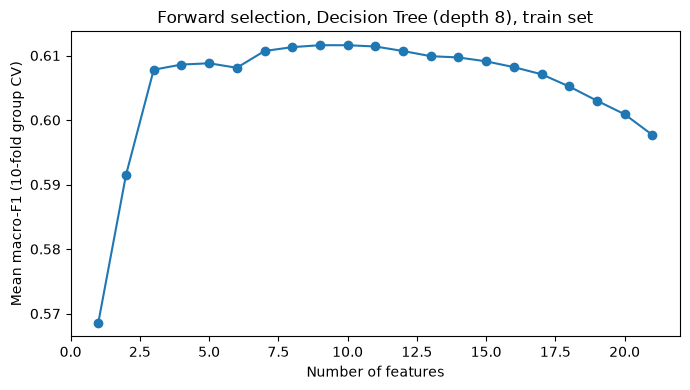

3 ['artist_popularity', 'log_followers', 'album_type_album', 'album_type_compilation', 'album_type_single']


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist["n_features"], hist["cv_macro_f1"], marker="o")
ax.set_xlabel("Number of features"); ax.set_ylabel("Mean macro-F1 (10-fold group CV)")
ax.set_title("Forward selection, Decision Tree (depth 8), train set")
fig.tight_layout(); fig.savefig("figures/fig6_forward_selection.png", dpi=200); plt.show()

k = hist.loc[hist["cv_macro_f1"] >= hist["cv_macro_f1"].max() - 0.005, "n_features"].min()
chosen = sum((groups[g] for g in hist["added"][:k]), [])
with open("selected_features.txt", "w") as f:
    f.write("\n".join(chosen))
print(k, chosen)

In [10]:
for k in [3, 5, 10, 21]:
    cols = sum((groups[g] for g in hist["added"][:k]), [])
    s = cross_val_score(model, X[cols], y, cv=folds, scoring="f1_macro", n_jobs=-1)
    print(k, round(s.mean(), 4), "±", round(s.std(), 4))

3 0.6078 ± 0.0093
5 0.6088 ± 0.0094
10 0.6116 ± 0.0099
21 0.5977 ± 0.0097


### Feature selection (train set only, 10-fold group CV by song)
- Filter (correlation ranking): artist_popularity (0.70) and log_followers (0.56) come out on top, then speechiness (−0.31), genre_broad_unknown (−0.27) and loudness (0.24). Tracks with no genre tag tend to be less popular, maybe because less-known artists don't get tagged.
- Wrapper (forward selection with a depth-8 decision tree, scored on macro-F1): artist_popularity, log_followers and album_type already get 0.608. The best score is 0.612 with 9 or 10 features, only 0.004 more. With all 21 features it drops to 0.598, so the extra features don't help.
- The lecture version of forward selection stops as soon as the score stops improving, which would be at 5 features (0.609). I ran all 21 steps instead so I could see the whole curve (Fig 6).
- I picked artist_popularity, log_followers and album_type, since that's the smallest set within 0.005 of the best score. They're saved in selected_features.txt.
- Fold spread is about ±0.009 to 0.010, so 3, 5 and 10 features score basically the same. 21 is a bit lower, but only by about one SD, so I wouldn't call it a big drop.
- The two methods don't fully agree. Genre ranked high in the filter but only came 19th in forward selection, because once the artist features are in, genre doesn't add much on top (they overlap).
- Forward selection is greedy and I only ran it with one model, so in R3 we still test all features vs the selected set vs no artist features.